# Malaria parasite detection in thin blood smear cells

**Problem.** Light microscopy of Giemsa-stained blood smears is the diagnostic reference for malaria across
sub-Saharan Africa, but reading a slide is slow, skilled work and its accuracy depends on the microscopist's
training and workload. I am building a screening model that classifies single segmented red blood cells as **Parasitized**
or **Uninfected**, so a smear can be triaged automatically and a microscopist's time is spent on the cells and
slides that need it.

**This notebook** covers dataset exploration, preprocessing, a custom CNN baseline, an optimised transfer-learning
model (MobileNetV2), evaluation, prediction functions and serialisation of the model that the production API serves
and that retraining starts from. Code that the service also uses lives in `src/`; the notebook imports it rather than
duplicating it, so what is evaluated here is exactly what is deployed.

**Positive class.** Parasitized. In screening, a missed infection (false negative) costs more than an unnecessary
second look, so recall on Parasitized is reported alongside F1 throughout.

In [1]:
import json, os, sys, time, random
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import roc_curve, precision_recall_curve, ConfusionMatrixDisplay, classification_report

from src.config import get_settings, CLASS_NAMES
from src import model as M
from src.preprocessing import load_image, resize_pad, compute_stats
from src.registry import ModelRegistry
from src.drift import build_reference, DRIFT_FEATURES

SEED = 42
# NB_SMOKE=1 runs every cell on a small subset with 1 epoch (used to validate the notebook quickly);
# the committed notebook is the full run (NB_SMOKE unset).
SMOKE = os.environ.get("NB_SMOKE") == "1"
LIMIT = 600 if SMOKE else 0
EP = (lambda n: 1) if SMOKE else (lambda n: n)
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed)
set_seed()
S = get_settings()
FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
print("TensorFlow", tf.__version__, "| CPU threads", os.cpu_count(), "| image size", S.image_size)

TensorFlow 2.18.0 | CPU threads 2 | image size 128


## 1. Data acquisition and provenance

**Source.** NIH/NLM malaria cell images (Rajaraman et al., *PeerJ* 2018): 27,558 single-cell crops from Giemsa-stained
thin smears of 150 *P. falciparum*-infected and 50 uninfected patients, photographed at Chittagong Medical College
Hospital, Bangladesh, and annotated by an expert slide reader at the Mahidol-Oxford Tropical Medicine Research Unit.
It is a U.S. Government work (public domain in the U.S.; attribution requested).

**Acquisition.** `scripts/acquire_data.py` pulls the images (from the NLM download or a git mirror that keeps the
original file names), verifies every file, de-duplicates by SHA-256, computes per-image descriptors, and writes
`data/manifest.csv` and `data/dataset_card.json`. It was run before this notebook:

```bash
python scripts/acquire_data.py --git-mirror https://github.com/TheODDYSEY/Malaria-Detection-Model
```

**Why the split is by patient.** Each file name starts with a slide identifier (e.g. `C100P61ThinF`). Infected patients
contribute both parasitized and uninfected cells, and cells from one slide share staining and illumination. A random
cell-level split would put the same patient in train and test and inflate the score, so the split assigns whole
patients to train/validation/test (70/15/15 of cells, balanced per class, seed 42).

In [2]:
card = json.loads((S.data_dir / "dataset_card.json").read_text())
manifest = pd.read_csv(S.data_dir / "manifest.csv")
print(json.dumps({k: card[k] for k in ["n_images", "n_patients", "split_strategy", "patient_overlap_between_splits",
                                       "patients_per_split", "licence"]}, indent=2))
counts = manifest.groupby(["split", "label"]).size().unstack().loc[["train", "val", "test"]]
counts["total"] = counts.sum(axis=1); counts["patients"] = manifest.groupby("split").patient_id.nunique()
counts

{
  "n_images": 27556,
  "n_patients": 201,
  "split_strategy": "patient-grouped (slide id from filename), no patient in more than one split",
  "patient_overlap_between_splits": 0,
  "patients_per_split": {
    "train": 140,
    "val": 31,
    "test": 30
  },
  "licence": "U.S. Government work (NLM) - public domain in the United States; attribution requested"
}


label,Parasitized,Uninfected,total,patients
split,,,,
train,9608,9609,19217,140
val,2056,2104,4160,31
test,2114,2065,4179,30


In [3]:
# Leakage checks: no patient and no identical image appears in more than one split
pid_sets = {s: set(manifest.loc[manifest.split == s, "patient_id"]) for s in ["train", "val", "test"]}
assert not (pid_sets["train"] & pid_sets["test"]) and not (pid_sets["train"] & pid_sets["val"]) and not (pid_sets["val"] & pid_sets["test"])
assert manifest.sha256.is_unique
print("patient overlap: 0 | duplicate images: 0 | 27,556 unique images (2 duplicate files removed upstream)")

patient overlap: 0 | duplicate images: 0 | 27,556 unique images (2 duplicate files removed upstream)


## 2. Exploratory data analysis

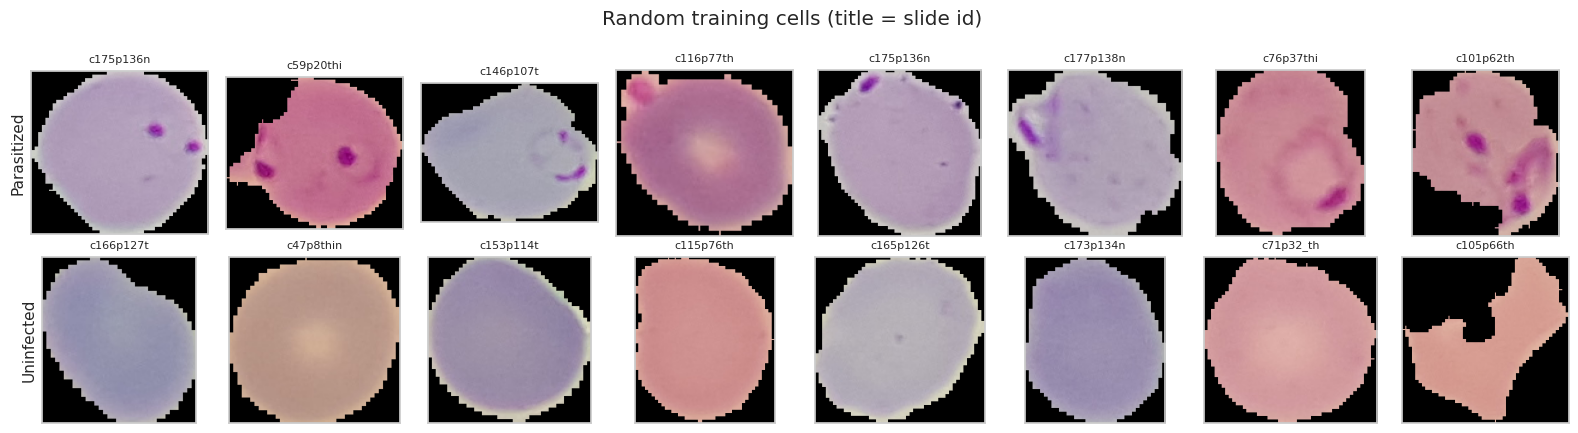

In [4]:
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for row, label in enumerate(["Parasitized", "Uninfected"]):
    sample = manifest[(manifest.label == label) & (manifest.split == "train")].sample(8, random_state=3)
    for ax, (_, r) in zip(axes[row], sample.iterrows()):
        ax.imshow(Image.open(S.data_dir / r.path)); ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{r.patient_id[:9]}", fontsize=8)
    axes[row, 0].set_ylabel(label, fontsize=11)
plt.suptitle("Random training cells (title = slide id)"); plt.tight_layout(); plt.savefig(FIG / "samples.png", dpi=110); plt.show()

Parasitized cells show one or more dark purple dots or rings (parasite chromatin and cytoplasm) on the pink
erythrocyte; uninfected cells are evenly stained. Crops sit on a black background, vary in size, and colour varies
visibly between slides.

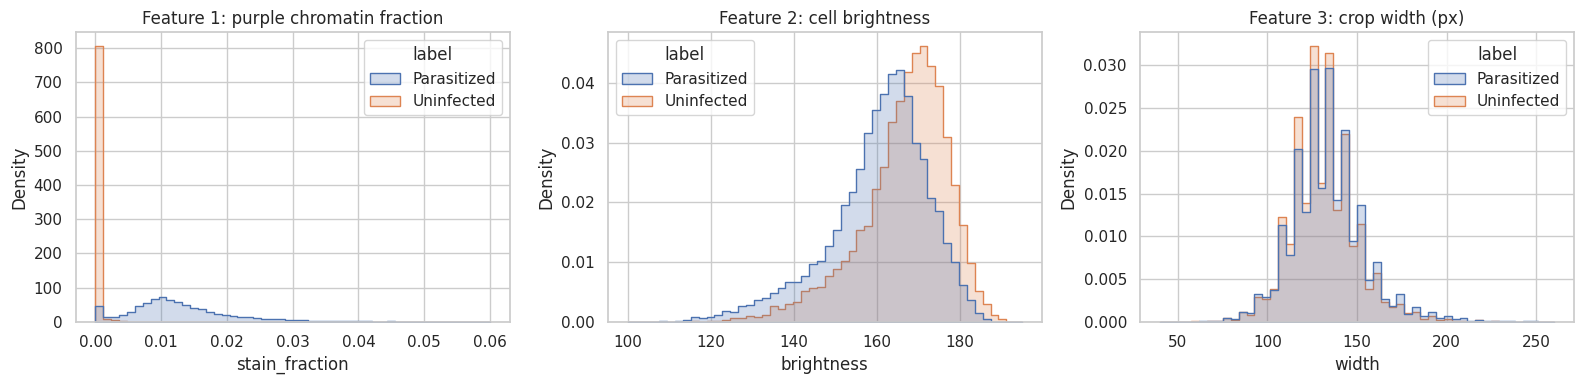

,median_parasitized,median_uninfected,single_feature_roc_auc
stain_fraction,0.0118,0.0000,0.9706
brightness,162.2183,168.3880,0.3382
width,133.0000,130.0000,0.5295
mean_g,147.3103,157.4870,0.3145
mean_b,152.3137,160.1609,0.3865
background_fraction,0.2774,0.2631,0.5806


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, xlim, title) in zip(axes, [("stain_fraction", (0, 0.06), "Feature 1: purple chromatin fraction"),
                                         ("brightness", (100, 195), "Feature 2: cell brightness"),
                                         ("width", (40, 260), "Feature 3: crop width (px)")]):
    sns.histplot(data=manifest, x=col, hue="label", bins=50, binrange=xlim, stat="density", common_norm=False,
                 element="step", ax=ax)
    ax.set_title(title)
plt.tight_layout(); plt.savefig(FIG / "feature_distributions.png", dpi=110); plt.show()

from sklearn.metrics import roc_auc_score
y_all = (manifest.label == "Parasitized").astype(int)
feat = pd.DataFrame({c: {"median_parasitized": manifest.loc[y_all == 1, c].median(),
                         "median_uninfected": manifest.loc[y_all == 0, c].median(),
                         "single_feature_roc_auc": roc_auc_score(y_all, manifest[c])}
                     for c in ["stain_fraction", "brightness", "width", "mean_g", "mean_b", "background_fraction"]}).T
feat.round(4)

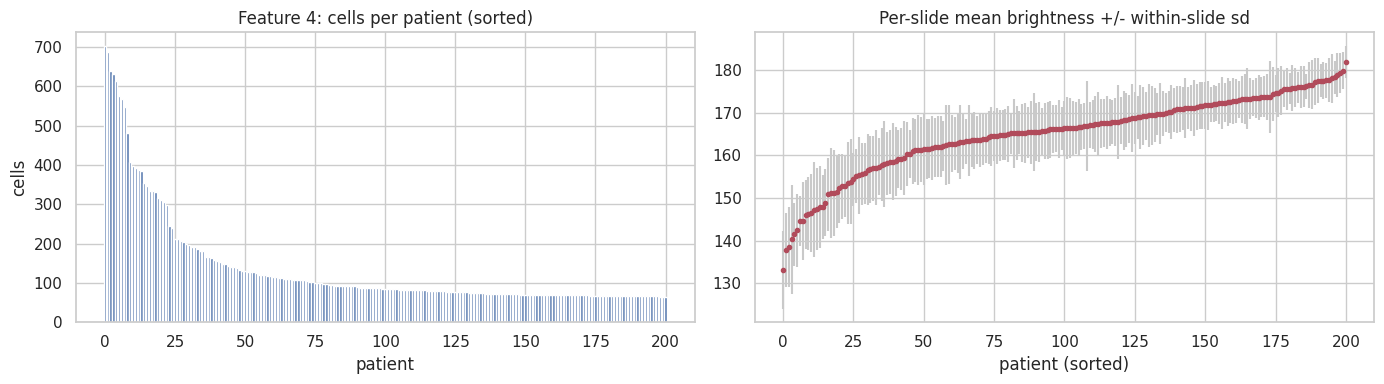

sd of slide means: 9.13 | mean within-slide sd: 6.54
uninfected-only patients: 50 | cells/patient min 65 median 85 max 702


In [6]:
slide = manifest.groupby("patient_id").agg(cells=("path", "size"), brightness=("brightness", "mean"),
                                           brightness_sd=("brightness", "std"),
                                           share_parasitized=("label", lambda s: (s == "Parasitized").mean()))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(range(len(slide)), slide.cells.sort_values(ascending=False).values, color="#5b7db1")
axes[0].set_title("Feature 4: cells per patient (sorted)"); axes[0].set_xlabel("patient"); axes[0].set_ylabel("cells")
order = slide.sort_values("brightness").index
axes[1].errorbar(range(len(order)), slide.loc[order, "brightness"], yerr=slide.loc[order, "brightness_sd"],
                 fmt=".", ecolor="#c9c9c9", color="#b14b5b")
axes[1].set_title("Per-slide mean brightness +/- within-slide sd"); axes[1].set_xlabel("patient (sorted)")
plt.tight_layout(); plt.savefig(FIG / "patients_and_slides.png", dpi=110); plt.show()
print(f"sd of slide means: {slide.brightness.std():.2f} | mean within-slide sd: {slide.brightness_sd.mean():.2f}")
print(f"uninfected-only patients: {(slide.share_parasitized == 0).sum()} | cells/patient min {slide.cells.min()} median {slide.cells.median():.0f} max {slide.cells.max()}")

### What the features show

1. **Purple chromatin fraction is the dominant signal.** The share of dark-purple pixels inside the cell
   (Giemsa-stained parasite chromatin) alone separates the classes with ROC-AUC ~0.97: about 62% of parasitized
   cells exceed 1% stained pixels against under 1% of uninfected cells. The CNN has to find a small, colour-defined
   structure, so I keep full colour and use 128 px inputs rather than shrinking further. The overlap region -
   parasitized cells with almost no visible stain (early rings, defocus) and uninfected cells with stain specks
   (platelets on top of the cell, stain precipitate) - is where I expect most errors and most label noise.
2. **Brightness reveals a slide-level batch effect.** Parasitized cells are a little darker overall, but the
   variation between slide means (sd ~9.1) is larger than within a slide (sd ~6.5). Slides differ in stain batch,
   smear thickness and illumination. This justifies (a) the patient-grouped split, (b) mild brightness/contrast
   augmentation, and (c) brightness and stain drift monitoring in production, since a new clinic or microscope will
   shift exactly these statistics.
3. **Cell size carries no class information.** Widths span 46-394 px (median ~130) with near-identical class
   distributions (ROC-AUC ~0.53), so the model cannot cheat on size. Inputs need a fixed shape: I scale the long
   side to 128 px and pad with black, preserving aspect ratio and matching the existing black background.
4. **Patients are unevenly represented** (65-702 cells each; 50 uninfected-only patients). Heavy slides could
   dominate a random split; grouping by patient keeps the test set representative of unseen people.

**Class balance.** The classes are balanced overall (13,778 each) and the split keeps each partition within half a
percentage point of 50/50, so I use unweighted binary cross-entropy and report threshold-independent metrics
(ROC-AUC, PR-AUC) as well.

## 3. Preprocessing and augmentation

`src/preprocessing.py` is shared by training, retraining and the API: decode and validate (format, corruption,
dimensions), convert to RGB, aspect-preserving resize to 128 px on a black canvas, scale to [-1, 1] (the
MobileNetV2 convention). Training adds label-preserving augmentation: flips and 90 degree rotations (a cell has no
canonical orientation) plus mild brightness/contrast jitter to mimic slide-to-slide staining. Images are cached as
uint8 arrays, the exact output of the online preprocessing function.

train (19217, 128, 128, 3) val (4160, 128, 128, 3) test (4179, 128, 128, 3) | 9.7s | positive share 0.500/0.494/0.506


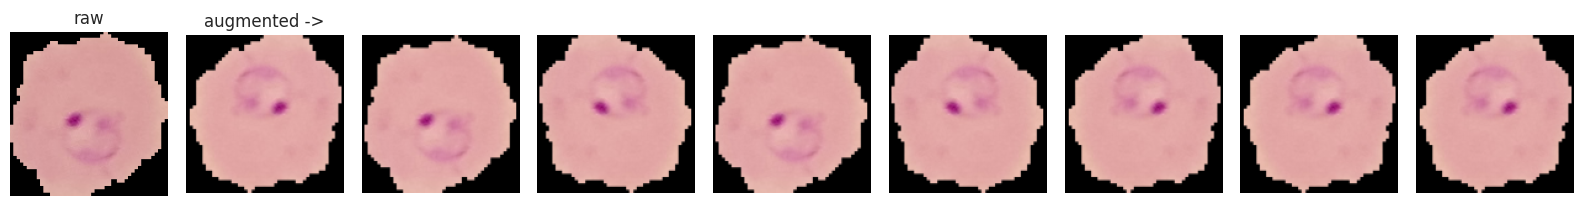

In [7]:
t0 = time.time()
x_tr, y_tr, rows_tr = M.load_split_arrays(S.data_dir, "train", S.image_size, limit=LIMIT)
x_va, y_va, rows_va = M.load_split_arrays(S.data_dir, "val", S.image_size, limit=LIMIT // 2)
x_te, y_te, rows_te = M.load_split_arrays(S.data_dir, "test", S.image_size, limit=LIMIT // 2)
print(f"train {x_tr.shape} val {x_va.shape} test {x_te.shape} | {time.time()-t0:.1f}s | positive share "
      f"{y_tr.mean():.3f}/{y_va.mean():.3f}/{y_te.mean():.3f}")

from src.preprocessing import augment_batch
demo = tf.cast(np.repeat(x_tr[:1], 8, axis=0), tf.float32) / 127.5 - 1
aug = augment_batch(demo).numpy()
fig, axes = plt.subplots(1, 9, figsize=(16, 2.2))
axes[0].imshow(Image.open(S.data_dir / rows_tr[0]["path"])); axes[0].set_title("raw")
for ax, a in zip(axes[1:], aug): ax.imshow((a + 1) / 2)
for ax in axes: ax.axis("off")
axes[1].set_title("augmented ->"); plt.tight_layout(); plt.savefig(FIG / "augmentation.png", dpi=110); plt.show()

## 4. Model 1 - custom CNN baseline

A four-block CNN trained from scratch (stride-2 stem, conv-BN-ReLU-maxpool blocks, global average pooling, dropout,
L2 weight decay; 251k parameters). Adam, `ReduceLROnPlateau`, and early stopping on validation loss with
best-weight restoration.

In [8]:
set_seed()
BATCH = 64
train_ds = M.make_dataset(x_tr, y_tr, BATCH, augment=True, shuffle=True)
val_ds = M.make_dataset(x_va, y_va, 128)
baseline = M.build_baseline_cnn(S.image_size, dropout=0.3, l2=1e-4)
M.compile_model(baseline, 1e-3)
fit_base = M.fit(baseline, train_ds, val_ds, epochs=EP(8), patience=3,
                 extra_callbacks=[tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=1, min_lr=1e-5)])
print(f"baseline: {fit_base.epochs_run} epochs in {fit_base.seconds/60:.1f} min")

Epoch 1/8


301/301 - 125s - 416ms/step - accuracy: 0.9355 - auc: 0.9766 - loss: 0.2171 - precision: 0.9559 - recall: 0.9131 - val_accuracy: 0.7517 - val_auc: 0.9755 - val_loss: 0.5751 - val_precision: 0.9990 - val_recall: 0.4981 - learning_rate: 0.0010


Epoch 2/8


301/301 - 95s - 317ms/step - accuracy: 0.9505 - auc: 0.9835 - loss: 0.1755 - precision: 0.9681 - recall: 0.9316 - val_accuracy: 0.9204 - val_auc: 0.9842 - val_loss: 0.2247 - val_precision: 0.9843 - val_recall: 0.8526 - learning_rate: 0.0010


Epoch 3/8


301/301 - 150s - 499ms/step - accuracy: 0.9536 - auc: 0.9852 - loss: 0.1642 - precision: 0.9706 - recall: 0.9356 - val_accuracy: 0.9546 - val_auc: 0.9879 - val_loss: 0.1548 - val_precision: 0.9592 - val_recall: 0.9484 - learning_rate: 0.0010


... (7 outputs left out)

301/301 - 106s - 353ms/step - accuracy: 0.9613 - auc: 0.9906 - loss: 0.1329 - precision: 0.9765 - recall: 0.9454 - val_accuracy: 0.9558 - val_auc: 0.9899 - val_loss: 0.1413 - val_precision: 0.9746 - val_recall: 0.9348 - learning_rate: 9.0000e-05


Epoch 8/8


301/301 - 113s - 375ms/step - accuracy: 0.9620 - auc: 0.9912 - loss: 0.1288 - precision: 0.9763 - recall: 0.9469 - val_accuracy: 0.9596 - val_auc: 0.9903 - val_loss: 0.1343 - val_precision: 0.9697 - val_recall: 0.9480 - learning_rate: 2.7000e-05


baseline: 8 epochs in 15.6 min


## 5. Model 2 - transfer learning with MobileNetV2

**Why MobileNetV2.** The service runs on CPU-only containers, so accuracy per FLOP matters: MobileNetV2 (3.5M
parameters, ~0.1 GFLOPs at 128 px) gives ImageNet features cheaply. ImageNet weights for the 128 px variant are
loaded from a pinned file (`scripts/fetch_pretrained.py` records the SHA-256).

**Head.** Global average pooling -> dropout -> dense(ReLU, L2) -> dropout -> sigmoid.

**Hyperparameter search.** To keep the search affordable on CPU, I extract frozen-backbone features once and tune
the head (dropout, width, learning rate, optimizer) on them; the winning head configuration is then used for the
full end-to-end model.

In [9]:
set_seed()
probe = M.build_transfer_model(S.image_size, S.pretrained_weights)
feat_extractor = tf.keras.Sequential([M.backbone(probe), tf.keras.layers.GlobalAveragePooling2D()])
t0 = time.time()
f_tr = feat_extractor.predict(M.make_dataset(x_tr, y_tr, 128), verbose=0)
f_va = feat_extractor.predict(M.make_dataset(x_va, y_va, 128), verbose=0)
print(f"features {f_tr.shape} in {time.time()-t0:.0f}s")

def head(dropout, units, l2=1e-4):
    reg = tf.keras.regularizers.l2(l2)
    return tf.keras.Sequential([tf.keras.Input((f_tr.shape[1],)), tf.keras.layers.Dropout(dropout),
                                tf.keras.layers.Dense(units, activation="relu", kernel_regularizer=reg),
                                tf.keras.layers.Dropout(dropout), tf.keras.layers.Dense(1, activation="sigmoid")])
grid = [dict(dropout=d, units=u, lr=lr, optimizer=o) for o in ["adam", "sgd"] for d in [0.2, 0.4]
        for u in [64, 128] for lr in ([1e-3, 3e-4] if o == "adam" else [1e-2])]
results = []
for cfg in grid:
    set_seed()
    h = head(cfg["dropout"], cfg["units"]); M.compile_model(h, cfg["lr"], cfg["optimizer"])
    hist = h.fit(f_tr, y_tr, validation_data=(f_va, y_va), epochs=EP(40), batch_size=128, verbose=0,
                 callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)])
    i = int(np.argmin(hist.history["val_loss"]))
    results.append({**cfg, "epochs": i + 1, "val_loss": hist.history["val_loss"][i], "val_acc": hist.history["val_accuracy"][i],
                    "val_auc": hist.history["val_auc"][i]})
search = pd.DataFrame(results).sort_values("val_loss").reset_index(drop=True)
search.to_csv(ROOT / "docs" / "hparam_search.csv", index=False)
search.round(4)

features (19217, 1280) in 83s


,dropout,units,lr,optimizer,epochs,val_loss,val_acc,val_auc
0,0.2,64,0.0003,adam,24,0.1671,0.9382,0.9849
1,0.2,64,0.0010,adam,12,0.1715,0.9353,0.9841
2,0.2,128,0.0003,adam,17,0.1746,0.9358,0.9848
3,0.2,64,0.0100,sgd,20,0.1791,0.9317,0.9839
4,0.2,128,0.0010,adam,11,0.1809,0.9358,0.9837
5,0.4,64,0.0003,adam,18,0.1907,0.9320,0.9813
6,0.4,64,0.0010,adam,12,0.1914,0.9286,0.9817
7,0.4,128,0.0010,adam,10,0.1989,0.9293,0.9819
8,0.4,128,0.0003,adam,12,0.1995,0.9288,0.9817
9,0.4,64,0.0100,sgd,12,0.2025,0.9305,0.9802


In [10]:
best = search.iloc[0].to_dict()
print("selected head:", {k: best[k] for k in ["dropout", "units", "lr", "optimizer"]})

# Stage 1: train the head end-to-end on images (frozen backbone, augmentation on)
set_seed()
tl = M.build_transfer_model(S.image_size, S.pretrained_weights, dropout=best["dropout"], dense_units=int(best["units"]))
M.compile_model(tl, best["lr"], best["optimizer"])
fit_s1 = M.fit(tl, train_ds, val_ds, epochs=EP(6), patience=2)

# Stage 2: unfreeze blocks 13-16 + head, cosine-decayed low LR (BatchNorm stays frozen)
n_trainable = M.unfreeze_top(tl, from_block=13)
steps = int(np.ceil(len(x_tr) / BATCH)) * EP(6)
M.compile_model(tl, tf.keras.optimizers.schedules.CosineDecay(1e-4, decay_steps=steps, alpha=0.05), "adam")
fit_s2 = M.fit(tl, train_ds, val_ds, epochs=EP(6), patience=3)
print(f"stage 1: {fit_s1.epochs_run} ep {fit_s1.seconds/60:.1f} min | stage 2: {fit_s2.epochs_run} ep "
      f"{fit_s2.seconds/60:.1f} min | trainable backbone layers {n_trainable}")

selected head: {'dropout': 0.2, 'units': 64, 'lr': 0.0003, 'optimizer': 'adam'}


Epoch 1/6


301/301 - 156s - 518ms/step - accuracy: 0.8571 - auc: 0.9349 - loss: 0.3361 - precision: 0.8662 - recall: 0.8446 - val_accuracy: 0.9123 - val_auc: 0.9730 - val_loss: 0.2464 - val_precision: 0.8756 - val_recall: 0.9587


Epoch 2/6


301/301 - 90s - 299ms/step - accuracy: 0.9014 - auc: 0.9631 - loss: 0.2558 - precision: 0.9108 - recall: 0.8899 - val_accuracy: 0.9216 - val_auc: 0.9767 - val_loss: 0.2150 - val_precision: 0.8994 - val_recall: 0.9475


Epoch 3/6


... (16 outputs left out)

301/301 - 147s - 487ms/step - accuracy: 0.9654 - auc: 0.9929 - loss: 0.1087 - precision: 0.9706 - recall: 0.9598 - val_accuracy: 0.9651 - val_auc: 0.9941 - val_loss: 0.1029 - val_precision: 0.9578 - val_recall: 0.9723


Epoch 6/6


301/301 - 138s - 457ms/step - accuracy: 0.9673 - auc: 0.9939 - loss: 0.1010 - precision: 0.9736 - recall: 0.9607 - val_accuracy: 0.9661 - val_auc: 0.9944 - val_loss: 0.0990 - val_precision: 0.9701 - val_recall: 0.9611


stage 1: 6 ep 9.7 min | stage 2: 6 ep 11.8 min | trainable backbone layers 25


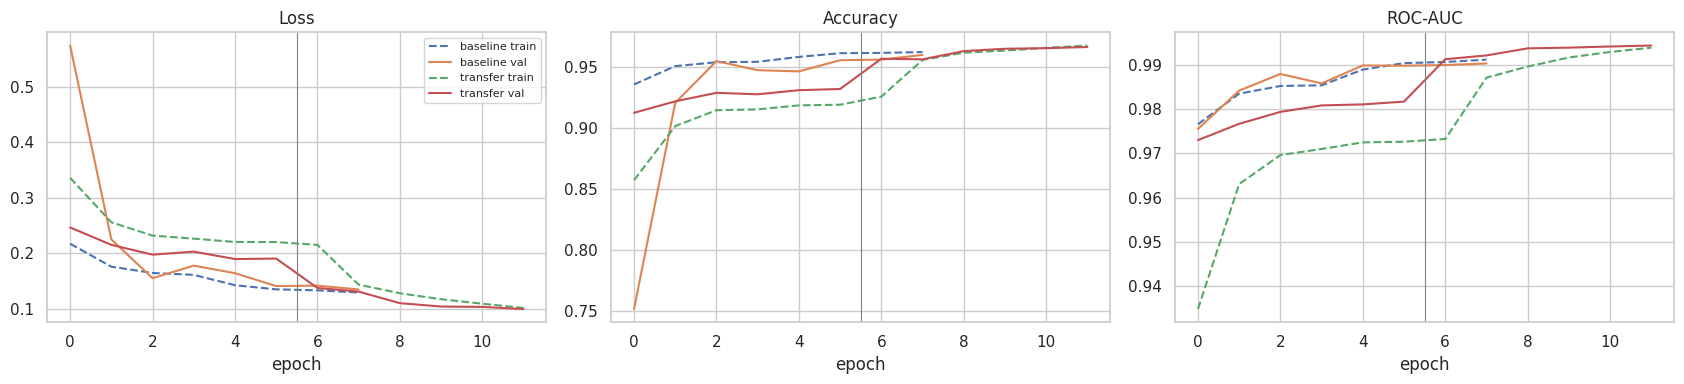

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
def curves(ax, key, title):
    ax.plot(fit_base.history[key], "--", label="baseline train"); ax.plot(fit_base.history["val_" + key], label="baseline val")
    s1 = len(fit_s1.history[key])
    xs = range(s1 + len(fit_s2.history[key]))
    ax.plot(xs, fit_s1.history[key] + fit_s2.history[key], "--", label="transfer train")
    ax.plot(xs, fit_s1.history["val_" + key] + fit_s2.history["val_" + key], label="transfer val")
    ax.axvline(s1 - 0.5, color="grey", lw=0.8); ax.set_title(title); ax.set_xlabel("epoch")
curves(axes[0], "loss", "Loss"); curves(axes[1], "accuracy", "Accuracy"); curves(axes[2], "auc", "ROC-AUC")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.savefig(FIG / "training_curves.png", dpi=110); plt.show()

## 6. Evaluation on the held-out test patients

In [12]:
p_base = M.predict_proba(baseline, x_te); p_tl = M.predict_proba(tl, x_te)
m_base = M.evaluate_probs(y_te, p_base); m_tl = M.evaluate_probs(y_te, p_tl)
keys = ["accuracy", "loss", "precision", "recall", "f1", "macro_f1", "specificity", "roc_auc", "pr_auc"]
cmp = pd.DataFrame({"Custom CNN baseline": {k: m_base[k] for k in keys}, "MobileNetV2 transfer": {k: m_tl[k] for k in keys}})
cmp.loc["parameters"] = [baseline.count_params(), tl.count_params()]
cmp.loc["train_minutes"] = [fit_base.seconds / 60, (fit_s1.seconds + fit_s2.seconds) / 60]
cmp.round(4)

,Custom CNN baseline,MobileNetV2 transfer
accuracy,0.9612,9.579000e-01
loss,0.1131,1.179000e-01
precision,0.9752,9.681000e-01
recall,0.9475,9.480000e-01
f1,0.9611,9.579000e-01
macro_f1,0.9612,9.579000e-01
specificity,0.9753,9.680000e-01
roc_auc,0.9924,9.913000e-01
pr_auc,0.9929,9.919000e-01
parameters,251361.0000,2.340033e+06


MobileNetV2 transfer - test set, threshold 0.5

              precision    recall  f1-score   support

  Uninfected     0.9478    0.9680    0.9578      2065
 Parasitized     0.9681    0.9480    0.9579      2114

    accuracy                         0.9579      4179
   macro avg     0.9580    0.9580    0.9579      4179
weighted avg     0.9581    0.9579    0.9579      4179



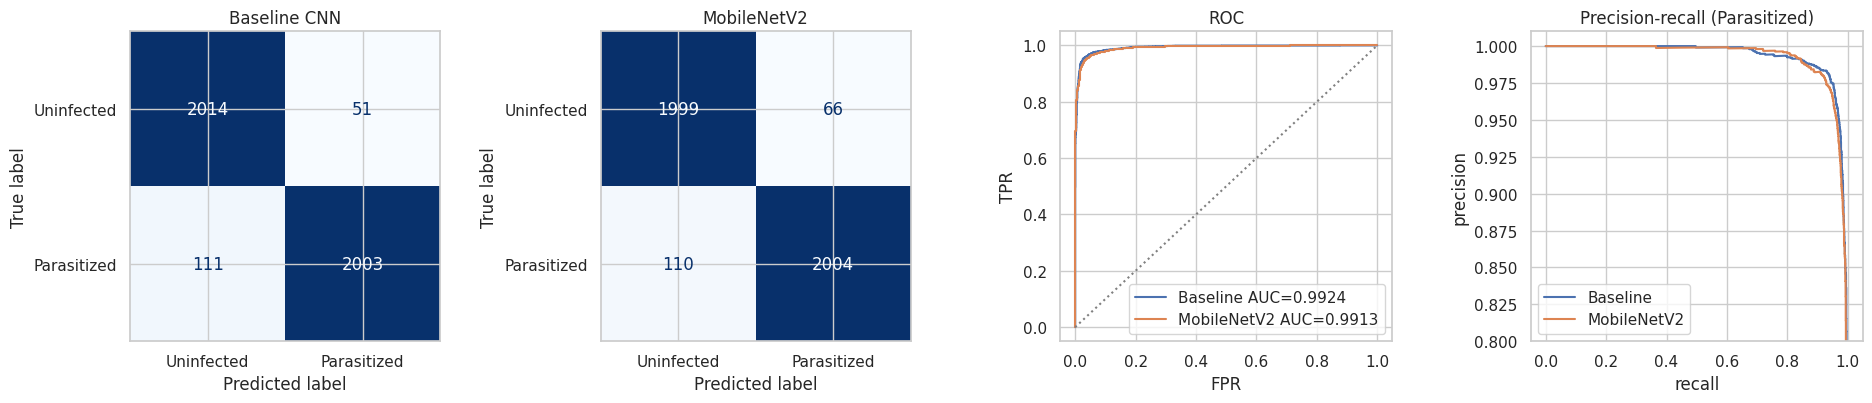

In [13]:
print("MobileNetV2 transfer - test set, threshold 0.5\n")
print(classification_report(y_te, (p_tl >= 0.5).astype(int), target_names=list(CLASS_NAMES), digits=4))
fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, p, name in [(axes[0], p_base, "Baseline CNN"), (axes[1], p_tl, "MobileNetV2")]:
    ConfusionMatrixDisplay.from_predictions(y_te, (p >= 0.5).astype(int), display_labels=list(CLASS_NAMES), ax=ax,
                                            colorbar=False, cmap="Blues", values_format="d"); ax.set_title(name)
for p, name in [(p_base, "Baseline"), (p_tl, "MobileNetV2")]:
    fpr, tpr, _ = roc_curve(y_te, p); axes[2].plot(fpr, tpr, label=f"{name} AUC={roc_auc_score(y_te, p):.4f}")
    pr, rc, _ = precision_recall_curve(y_te, p); axes[3].plot(rc, pr, label=name)
axes[2].plot([0, 1], [0, 1], ":", c="grey"); axes[2].set(title="ROC", xlabel="FPR", ylabel="TPR"); axes[2].legend()
axes[3].set(title="Precision-recall (Parasitized)", xlabel="recall", ylabel="precision", ylim=(0.8, 1.01)); axes[3].legend()
plt.tight_layout(); plt.savefig(FIG / "evaluation.png", dpi=110); plt.show()

In [14]:
# Operating points: what recall/specificity trade-off does the threshold give?
ops = []
for t in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    mm = M.evaluate_probs(y_te, p_tl, threshold=t)
    ops.append({"threshold": t, "recall (sensitivity)": mm["recall"], "specificity": mm["specificity"],
                "precision": mm["precision"], "f1": mm["f1"], "missed infected cells": mm["confusion_matrix"]["matrix"][1][0]})
pd.DataFrame(ops).round(4)

,threshold,recall (sensitivity),specificity,precision,f1,missed infected cells
0,0.2,0.9730,0.9220,0.9274,0.9497,57
1,0.3,0.9645,0.9467,0.9488,0.9566,75
2,0.4,0.9570,0.9564,0.9574,0.9572,91
3,0.5,0.9480,0.9680,0.9681,0.9579,110
4,0.6,0.9357,0.9729,0.9725,0.9537,136
5,0.7,0.9234,0.9797,0.9789,0.9503,162


In [15]:
# Error analysis 1: are errors concentrated in particular patients?
te = pd.DataFrame(rows_te); te[["brightness", "stain_fraction"]] = te[["brightness", "stain_fraction"]].astype(float); te["y"] = y_te; te["p"] = p_tl; te["pred"] = (p_tl >= 0.5).astype(int); te["err"] = te.y != te.pred
by_pat = te.groupby("patient_id").agg(cells=("err", "size"), errors=("err", "sum"), error_rate=("err", "mean"),
                                      brightness=("brightness", "mean")).sort_values("error_rate", ascending=False)
print(f"test patients: {len(by_pat)} | patients with zero errors: {(by_pat.errors == 0).sum()}")
print(f"errors in the 3 worst patients: {by_pat.errors.head(3).sum()} of {te.err.sum()} total")
by_pat.head(8).round(3)

test patients: 30 | patients with zero errors: 6
errors in the 3 worst patients: 32 of 176 total


,cells,errors,error_rate,brightness
patient_id,,,,
c92p53thinf,93,17,0.183,158.119
c110p71thinf,93,9,0.097,167.624
c104p65thinf,82,6,0.073,176.061
c39p4thinf,687,48,0.070,162.666
c95p56thinf,92,6,0.065,161.282
c138p99thinf,74,4,0.054,173.492
c91p52thinf,333,18,0.054,177.619
c157p118thinf,107,5,0.047,137.715


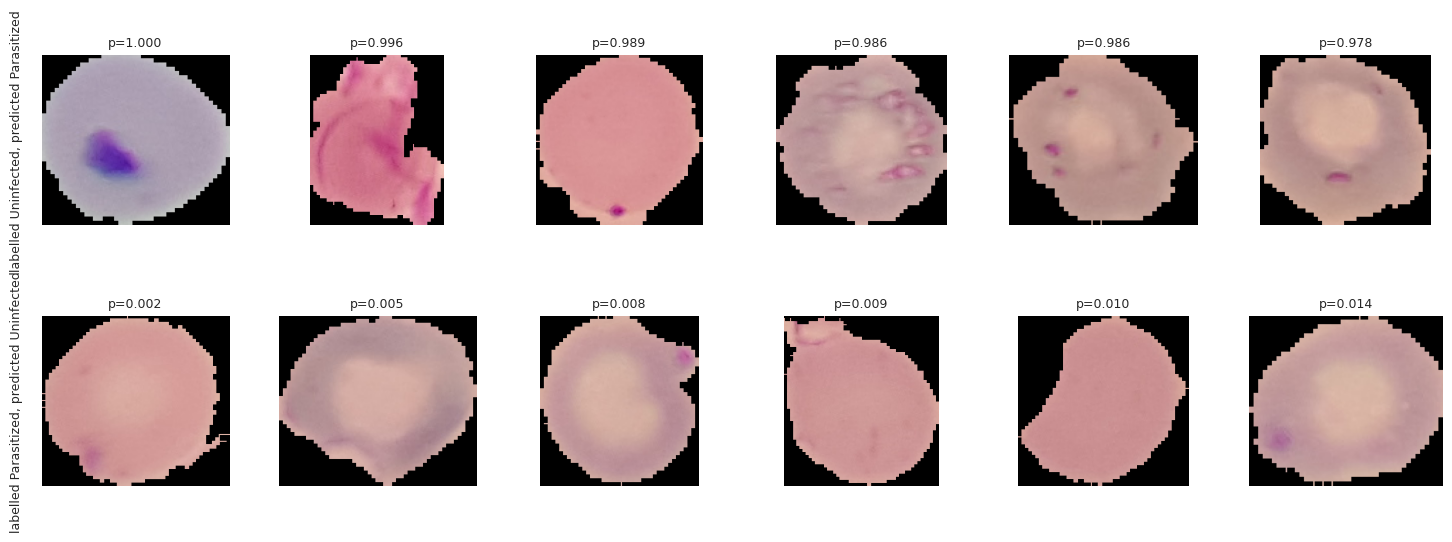

err          correct: median stain  error: median stain
y                                                      
Uninfected                  0.0000               0.0036
Parasitized                 0.0121               0.0004


In [16]:
# Error analysis 2: look at the most confident mistakes and at the stain feature for errors
fp = te[(te.y == 0) & (te.pred == 1)].sort_values("p", ascending=False).head(6)
fn = te[(te.y == 1) & (te.pred == 0)].sort_values("p").head(6)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for row, (df, title) in enumerate([(fp, "labelled Uninfected, predicted Parasitized"), (fn, "labelled Parasitized, predicted Uninfected")]):
    for ax, (_, r) in zip(axes[row], df.iterrows()):
        ax.imshow(Image.open(S.data_dir / r.path)); ax.set_title(f"p={r.p:.3f}", fontsize=9); ax.axis("off")
    axes[row, 0].text(-0.1, 0.5, title, transform=axes[row, 0].transAxes, rotation=90, va="center", ha="right", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "errors.png", dpi=110); plt.show()
print(te.groupby(["y", "err"]).stain_fraction.median().unstack().rename(index={0: "Uninfected", 1: "Parasitized"},
      columns={False: "correct: median stain", True: "error: median stain"}).round(4))

## 7. Prediction functions

In [17]:
from src.prediction import Predictor
from src.preprocessing import to_uint8_array

def predict_image(path, model=tl):
    """Notebook-level single-image prediction using the shared preprocessing path."""
    img = load_image(Path(path).read_bytes())
    p = float(M.predict_proba(model, to_uint8_array(img, S.image_size)[None])[0])
    label = CLASS_NAMES[int(p >= 0.5)]
    return {"predicted_class": label, "confidence": max(p, 1 - p), "p_parasitized": p}

check = te.groupby("label").sample(5, random_state=7)
out = pd.DataFrame([{"file": Path(r.path).name[:38], "true": r.label, **predict_image(S.data_dir / r.path)} for _, r in check.iterrows()])
out["correct"] = out.true == out.predicted_class
out.round(4)

,file,true,predicted_class,confidence,p_parasitized,correct
0,C82P43ThinF_IMG_20150817_123824_cell_1,Parasitized,Parasitized,1.0000,1.0000,True
1,C91P52ThinF_IMG_20150821_124937_cell_1,Parasitized,Parasitized,0.9821,0.9821,True
2,C39P4thinF_original_IMG_20150622_11011,Parasitized,Parasitized,1.0000,1.0000,True
3,C107P68ThinF_IMG_20150924_222415_cell_,Parasitized,Parasitized,0.9896,0.9896,True
4,C39P4thinF_original_IMG_20150622_11035,Parasitized,Parasitized,1.0000,1.0000,True
5,C82P43ThinF_IMG_20150817_123824_cell_1,Uninfected,Uninfected,0.9918,0.0082,True
6,C13NThinF_IMG_20150614_131417_cell_91.,Uninfected,Uninfected,0.9954,0.0046,True
7,C91P52ThinF_IMG_20150821_124739_cell_1,Uninfected,Uninfected,0.9900,0.0100,True
8,C138P99ThinF_IMG_20151005_171116_cell_,Uninfected,Uninfected,0.9967,0.0033,True
9,C209ThinF_IMG_20151029_160721_cell_163,Uninfected,Uninfected,0.9997,0.0003,True


## 8. Serialise the model for production

The transfer model is saved as version `v1` in the file-based registry (`models/`) with its metrics, data lineage,
hyperparameters and a drift reference (decile bins of brightness, stain fraction, colour and size over the training
set). It becomes the active model that the API serves, and **the starting point for every retraining run**.

In [18]:
reg = ModelRegistry(S.models_dir)
train_rows = manifest[manifest.split == "train"]
reference = build_reference({f: train_rows[f].tolist() for f in DRIFT_FEATURES})
m_val = M.evaluate_probs(y_va, M.predict_proba(tl, x_va))
metadata = {
    "architecture": "MobileNetV2 (ImageNet, alpha=1.0, 128px) + GAP/Dropout/Dense head",
    "framework": f"tensorflow {tf.__version__}",
    "image_size": S.image_size, "class_names": list(CLASS_NAMES), "positive_class": "Parasitized",
    "preprocessing": "RGB, aspect-preserving resize to 128 + black pad, scale to [-1,1]",
    "hyperparameters": {"head": {k: (float(best[k]) if k != "optimizer" else best[k]) for k in ["dropout", "units", "lr"]} | {"optimizer": best["optimizer"]},
                        "stage1_epochs": fit_s1.epochs_run, "stage2_epochs": fit_s2.epochs_run,
                        "finetune_from_block": 13, "stage2_lr": "cosine 1e-4 -> 5e-6", "batch_size": BATCH,
                        "augmentation": "flips, rot90, brightness 0.08, contrast 0.9-1.1"},
    "training_data": {"source": "NIH/NLM malaria cell images", "split_seed": card["split_seed"],
                      "n_train": int(len(y_tr)), "n_val": int(len(y_va)), "n_test": int(len(y_te)),
                      "uploaded_samples": 0},
    "metrics": {"test": m_tl, "val": m_val},
    "baseline_metrics": {"test": m_base},
    "history": {"stage1": fit_s1.history, "stage2": fit_s2.history},
    "drift_reference": reference,
    "parent_version": None,
    "trigger": "initial training (notebook)",
    "summary": {"test_accuracy": m_tl["accuracy"], "test_f1": m_tl["f1"], "test_recall": m_tl["recall"],
                "test_roc_auc": m_tl["roc_auc"]},
}
version = reg.register(tl, metadata, status="candidate", version="v1")
reg.promote(version, reason="initial model from notebook")
baseline.save(S.models_dir / "baseline_cnn.keras")
print("registered and promoted", version, "->", reg.model_path(version))

# Round-trip check: the production Predictor loads the artifact and agrees with the in-memory model
pred = Predictor(S); pred.refresh(force=True)
x_chk = x_te[:64]
assert np.allclose(pred.predict_arrays(x_chk), M.predict_proba(tl, x_chk), atol=1e-4)
print("serving model matches notebook model on 64 test images; version", pred.version)

registered and promoted v1 -> /home/claude/malaria-mlops/models/v1/model.keras


serving model matches notebook model on 64 test images; version v1


## 9. Is transfer learning worth it here?

On the test patients the two models are close, and the baseline is slightly ahead. Three questions decide which one
should be deployed: is the gap real, how do the models behave when slides look different from the training slides
(the batch effect found in the EDA), and what does each cost at inference time? These cells reload both models from
their saved artifacts, which also confirms the serialised files are the ones evaluated above.

accuracy(transfer) - accuracy(baseline) = -0.0034; 95% patient-bootstrap CI [-0.0120, +0.0067]; P(transfer better) = 0.25


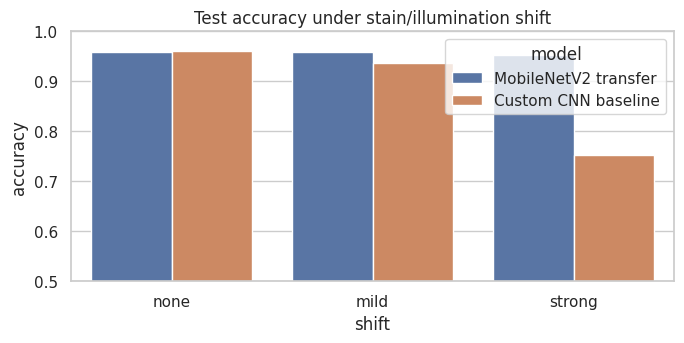

single-image CPU latency (ms): {'MobileNetV2 transfer': 8.75, 'Custom CNN baseline': 2.23}


,shift,model,accuracy,recall,specificity,f1,roc_auc
0,none,MobileNetV2 transfer,0.9579,0.9480,0.9680,0.9579,0.9913
1,none,Custom CNN baseline,0.9612,0.9475,0.9753,0.9611,0.9924
2,mild,MobileNetV2 transfer,0.9581,0.9447,0.9719,0.9580,0.9906
3,mild,Custom CNN baseline,0.9368,0.9669,0.9061,0.9393,0.9877
4,strong,MobileNetV2 transfer,0.9519,0.9305,0.9738,0.9514,0.9894
5,strong,Custom CNN baseline,0.7523,0.9858,0.5133,0.8011,0.9730


In [19]:
tl_saved = M.load_keras(S.models_dir / "v1" / "model.keras")
base_saved = M.load_keras(S.models_dir / "baseline_cnn.keras")
p_tl_s, p_base_s = M.predict_proba(tl_saved, x_te), M.predict_proba(base_saved, x_te)

# (a) Patient-level bootstrap of the accuracy difference: resample whole test patients, because cells from one
#     slide are correlated and a cell-level bootstrap would understate the uncertainty.
pid = np.array([r["patient_id"] for r in rows_te]); patients = np.unique(pid)
cells_of = {p: np.where(pid == p)[0] for p in patients}
rng = np.random.default_rng(0); diffs = []
for _ in range(2000):
    s = np.concatenate([cells_of[p] for p in rng.choice(patients, len(patients))])
    diffs.append(((p_tl_s[s] >= .5) == y_te[s]).mean() - ((p_base_s[s] >= .5) == y_te[s]).mean())
diffs = np.array(diffs)
point = ((p_tl_s >= .5) == y_te).mean() - ((p_base_s >= .5) == y_te).mean()
print(f"accuracy(transfer) - accuracy(baseline) = {point:+.4f}; 95% patient-bootstrap CI "
      f"[{np.percentile(diffs, 2.5):+.4f}, {np.percentile(diffs, 97.5):+.4f}]; P(transfer better) = {(diffs > 0).mean():.2f}")

# (b) Robustness to a stain / illumination shift (darker, bluer slides: thicker smear, different Giemsa batch or lamp)
from PIL import ImageEnhance
def shift_split(brightness, red, blue):
    out = np.empty_like(x_te)
    for i, r in enumerate(rows_te):
        img = ImageEnhance.Brightness(Image.open(S.data_dir / r["path"]).convert("RGB")).enhance(brightness)
        R, G, B = img.split()
        img = Image.merge("RGB", (R.point(lambda v: v * red), G, B.point(lambda v: min(255, v * blue))))
        out[i] = to_uint8_array(img, S.image_size)
    return out
robust = []
for name, args in [("none", None), ("mild", (0.85, 0.95, 1.06)), ("strong", (0.72, 0.90, 1.12))]:
    xs = x_te if args is None else shift_split(*args)
    for mname, mdl in [("MobileNetV2 transfer", tl_saved), ("Custom CNN baseline", base_saved)]:
        mm = M.evaluate_probs(y_te, M.predict_proba(mdl, xs))
        robust.append({"shift": name, "model": mname, "accuracy": mm["accuracy"], "recall": mm["recall"],
                       "specificity": mm["specificity"], "f1": mm["f1"], "roc_auc": mm["roc_auc"]})
robust = pd.DataFrame(robust)
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.barplot(data=robust, x="shift", y="accuracy", hue="model", ax=ax); ax.set_ylim(0.5, 1); ax.set_title("Test accuracy under stain/illumination shift")
plt.tight_layout(); plt.savefig(FIG / "robustness.png", dpi=110); plt.show()

# (c) CPU inference cost for one image (what the API does per request)
lat = {}
for mname, mdl in [("MobileNetV2 transfer", tl_saved), ("Custom CNN baseline", base_saved)]:
    f = tf.function(lambda a, m=mdl: m(a, training=False)); one = x_te[:1].astype("float32") / 127.5 - 1; f(one)
    t0 = time.perf_counter(); [f(one) for _ in range(200)]; lat[mname] = (time.perf_counter() - t0) / 200 * 1000
print("single-image CPU latency (ms):", {k: round(v, 2) for k, v in lat.items()})
robust.round(4)

## 10. Discussion

**Results.** On 4,179 cells from 30 patients the model never saw, the deployed MobileNetV2 transfer model reaches
95.79% accuracy, precision 0.968, recall 0.948, F1 0.958, ROC-AUC 0.991 and PR-AUC 0.992 (loss 0.118). The custom CNN
baseline scores 96.12% / 0.975 / 0.948 / 0.961 / 0.992. The 0.34-point gap is not meaningful: the patient-level 95%
bootstrap interval for the difference spans roughly -1.2 to +0.7 points. Both models clear the frozen-feature heads from the
search (~93.8% validation accuracy), so fine-tuning the top MobileNetV2 blocks was worth about three points.

**Why the transfer model is the one deployed.** Under a simulated stain/illumination shift the baseline breaks
down - its accuracy drops to about 94% for a mild shift and 75% for a strong one, because it starts calling almost
every darker cell parasitized (recall up, specificity collapsing) - while the transfer model stays at about 95-96%.
The EDA showed that slide-to-slide staining variation is the largest non-biological effect in this data, and new
clinics will add more of it, so robustness to exactly this shift matters more than a third of a point on in-distribution
test cells. The price is latency (8.8 ms vs 2.2 ms per image, measured on this CPU), which the load tests show is
affordable. A small, from-scratch CNN can memorise this dataset's colour statistics; ImageNet features generalise better
to colour changes.

**Errors and generalisation.** Errors are concentrated by patient: 6 of 30 test patients have no errors, and the worst
three account for 32 of the 176 errors; one slide (c92p53) has an 18% error rate. Validation and test accuracy agree
within about one point, and training accuracy is not far above them, so the model is not overfitting cells - the
remaining variance is between patients. The confident mistakes match the stain analysis: missed parasitized cells
have almost no purple stain (median stain fraction 0.0004 vs 0.012 for correctly detected ones; early ring forms,
defocused parasites, or label noise), while false positives carry stain specks (median 0.0036 vs 0.000; platelets or
stain debris over the cell). Some of these look mislabelled on inspection, consistent with known noise in this dataset.

**Class balance and threshold.** The classes are balanced, so no reweighting was needed. The threshold is a
clinical choice: at 0.5 the model misses 110 of 2,114 infected cells (recall 0.948, specificity 0.968); at 0.3 it misses
75 (recall 0.965) for a specificity of 0.947. Because the service flags results within 0.15 of the threshold for review,
the deployment keeps 0.5 and routes uncertain cells to a microscopist; a screening programme that prefers sensitivity can
lower `SMEAR_DECISION_THRESHOLD` without retraining.

**Limitations.** One hospital, one microscope setup and one species (*P. falciparum*); pre-segmented cells; patient-level
results come from 30 test patients, so per-patient estimates are noisy; the shift experiment is synthetic. A cell-level
classifier is one component of slide-level diagnosis, which also needs cell segmentation and parasitaemia estimation.
Before any clinical use the model would need prospective evaluation on slides from the clinics that would use it - the
retraining and feedback loop in this system is built for exactly that.